# MultiEdgeFit Functions

Based on VirtualBeamline by Mario Delgado Jaime


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit.minimizer import Minimizer, MinimizerResult

from mmg_toolbox.xas import load_xas_scans, SpectraContainer
from mmg_toolbox.xas.multi_edge_fit_parameters import prepare_components
from mmg_toolbox.xas.multi_edge_fit_models import BackgroundThreeRegionModel, DoubleLEdgeModel

In [2]:
files1, file2 = '/dls/science/groups/das/ExampleData/hdfmap_tests/i10/i10-1-37436.nxs', '/dls/science/groups/das/ExampleData/hdfmap_tests/i10/i10-1-37439.nxs'
spectra1, spectra2 = load_xas_scans(files1, file2, dls_loader=True)

In [25]:
class TwoComponentFitter:
    def __init__(self, spectra1: SpectraContainer, spectra2: SpectraContainer):
        self.spectrum1 = spectra1.spectra['tey']
        self.spectrum2 = spectra2.spectra['tey']

        self.edge1 = DoubleLEdgeModel(prefix='c1_')
        self.background1 = BackgroundThreeRegionModel(prefix='c1_')
        self.edge2 = DoubleLEdgeModel(prefix='c2_')
        self.background2 = BackgroundThreeRegionModel(prefix='c2_')
        self.model1 = self.edge1 + self.background1
        self.model2 = self.edge2 + self.background2

        self.edge_params1 = self.edge1.guess(self.spectrum1.signal, self.spectrum1.energy)
        self.edge_params2 = self.edge2.guess(self.spectrum2.signal, self.spectrum2.energy)
        self.bkg_params1 = self.background1.guess(self.spectrum1.signal, self.spectrum1.energy)
        self.bkg_params2 = self.background2.guess(self.spectrum2.signal, self.spectrum2.energy)
        self.params = self.edge_params1 + self.edge_params2 + self.bkg_params1 + self.bkg_params2
        self.initial_params = self.params.copy()
        self.fit_params = self.params.copy()

        self.minimizer = Minimizer(
            self.residuals,
            self.params,
        )
        self.result: MinimizerResult | None = None

        # self.params['c1_slope2'].expr = 'c1_slope1'

    def eval1(self) -> np.ndarray:
        return self.model1.eval(self.params, energy=self.spectrum1.energy)

    def eval2(self) -> np.ndarray:
        return self.model2.eval(self.params, energy=self.spectrum2.energy)

    def plot1(self, axes: plt.Axes, *args, **kwargs):
        axes.plot(self.spectrum1.energy, self.eval1(), *args, **kwargs)

    def plot2(self, axes: plt.Axes, *args, **kwargs):
        axes.plot(self.spectrum2.energy, self.eval2(), *args, **kwargs)

    def residuals(self, params) -> np.ndarray:
        yfit1 = self.model1.eval(params, energy=self.spectrum1.energy)
        yfit2 = self.model2.eval(params, energy=self.spectrum2.energy)
        return np.concatenate([
            yfit1 - self.spectrum1.signal,
            yfit2 - self.spectrum2.signal,
        ])

    def fit(self) -> MinimizerResult:
        self.result = self.minimizer.minimize()
        self.params = self.result.params
        return self.result


In [26]:
my_model = TwoComponentFitter(spectra1, spectra2)

for name, param in my_model.params.items():
    print(param)

<Parameter 'c1_intensity_l3', value=0.06390301534492009, bounds=[0.03195150767246004:0.12780603068984017]>
<Parameter 'c1_e0_l3', value=708.9953, bounds=[np.float64(707.4953):np.float64(712.9953)]>
<Parameter 'c1_spin_orbit_2p', value=8.2 (fixed), bounds=[8.1:8.299999999999999]>
<Parameter 'c1_gaussian_fraction', value=0.0, bounds=[0:1]>
<Parameter 'c1_width_l3', value=0.3, bounds=[0.2:0.5]>
<Parameter 'c1_width_l2', value=0.5, bounds=[0.3:1]>
<Parameter 'c1_l2_intensity_ratio', value=0.5 (fixed), bounds=[0.1:1.0]>
<Parameter 'c1_l2_energy_factor', value=1.5 (fixed), bounds=[1.0:2.0]>
<Parameter 'c2_intensity_l3', value=0.06379483658382074, bounds=[0.03189741829191037:0.12758967316764147]>
<Parameter 'c2_e0_l3', value=708.9666000000001, bounds=[np.float64(707.4666000000001):np.float64(712.9666000000001)]>
<Parameter 'c2_spin_orbit_2p', value=8.2 (fixed), bounds=[8.1:8.299999999999999]>
<Parameter 'c2_gaussian_fraction', value=0.0, bounds=[0:1]>
<Parameter 'c2_width_l3', value=0.3, boun

In [27]:
print(my_model.residuals(my_model.params))

[0.00050097 0.00049504 0.00046071 ... 0.05756713 0.05777793 0.05772839]


In [28]:
result = my_model.fit()

print(result)

In [29]:
for name, param in my_model.params.items():
    print(param)

<Parameter 'c1_intensity_l3', value=0.06390301534492009, bounds=[0.03195150767246004:0.12780603068984017]>
<Parameter 'c1_e0_l3', value=708.9953, bounds=[np.float64(707.4953):np.float64(712.9953)]>
<Parameter 'c1_spin_orbit_2p', value=8.2 (fixed), bounds=[8.1:8.299999999999999]>
<Parameter 'c1_gaussian_fraction', value=0.0, bounds=[0:1]>
<Parameter 'c1_width_l3', value=0.3, bounds=[0.2:0.5]>
<Parameter 'c1_width_l2', value=0.5, bounds=[0.3:1]>
<Parameter 'c1_l2_intensity_ratio', value=0.5 (fixed), bounds=[0.1:1.0]>
<Parameter 'c1_l2_energy_factor', value=1.5 (fixed), bounds=[1.0:2.0]>
<Parameter 'c2_intensity_l3', value=0.06379483658382074, bounds=[0.03189741829191037:0.12758967316764147]>
<Parameter 'c2_e0_l3', value=708.9666000000001, bounds=[np.float64(707.4666000000001):np.float64(712.9666000000001)]>
<Parameter 'c2_spin_orbit_2p', value=8.2 (fixed), bounds=[8.1:8.299999999999999]>
<Parameter 'c2_gaussian_fraction', value=0.0, bounds=[0:1]>
<Parameter 'c2_width_l3', value=0.3, boun

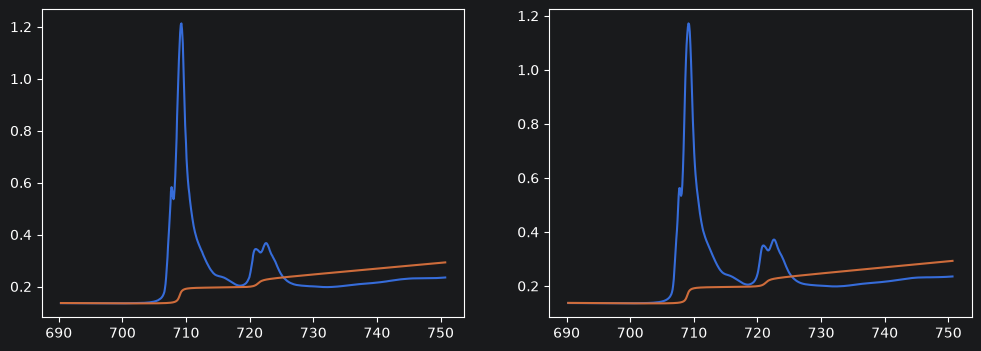

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
my_model.spectrum1.plot(ax1, label="spectrum1")
my_model.spectrum2.plot(ax2,label="spectrum2")
my_model.plot1(ax1, label='Fit Bkg1')
my_model.plot2(ax2, label='Fit Bkg2')